In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from keras.datasets import mnist
from keras.layers import Input,Dense
from keras.models import Model
from keras.preprocessing import image

In [2]:
(X_train, _),(X_test, _) = mnist.load_data()

In [3]:
print("X_train Shape", X_train.shape)
print("X_test Shape", X_test.shape)

X_train Shape (60000, 28, 28)
X_test Shape (10000, 28, 28)


<h2>Preprocess the data</h2>

In [ ]:
def pre_process(X):
    X = X/255.0
    X = X.reshape((len(X), 784))
    return X

X_train = pre_process(X_train)  
X_test = pre_process(X_test)

print("X_train Shape", X_train.shape)
print("X_test Shape", X_test.shape)

X_train Shape (60000, 784)
X_test Shape (10000, 784)


<h2>Visualize the digits</h2>

In [11]:
def show_data(X, n=10, height=28, width=28, title=''):
    plt.figure(figsize=(10,3))
    for i in range(n):
        ax = plt.subplot(2,n,i+1)
        plt.imshow(X[i].reshape((height,width)))
        plt.gray()
        ax.get_xaxis().set_visible(False)
        ax.get_yaxis().set_visible(False)
    plt.suptitle(title, fontsize = 20)

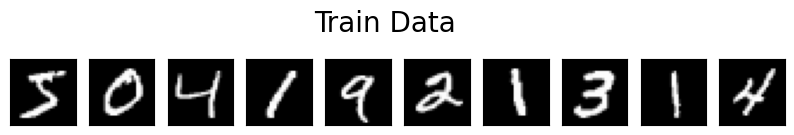

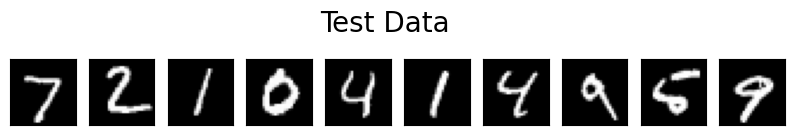

In [12]:
show_data(X_train,title="Train Data")
show_data(X_test,title="Test Data")

<h2>Build the digit Autoencoder</h2>

In [13]:
input_dim,output_dim = 784,784
encode_dim = 100
hidden_dim = 256

In [14]:
#encoder
input_layer = Input(shape=(input_dim,),name='INPUT')
hidden_layer_1 = Dense(hidden_dim, activation='relu', name='HIDDEN_1')(input_layer)

#code
code_layer = Dense(encode_dim, activation='relu', name='CODE')(hidden_layer_1)

#decoder
hidden_layer_2 = Dense(hidden_dim, activation='relu', name='HIDDEN_2')(code_layer)
output_layer = Dense(output_dim, activation='sigmoid', name='OUTPUT')(hidden_layer_2)

In [15]:
AE = Model(input_layer,output_layer)
AE.compile(optimizer='adam', loss='binary_crossentropy')
AE.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ INPUT (InputLayer)                   │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ HIDDEN_1 (Dense)                     │ (None, 256)                 │         200,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ CODE (Dense)                         │ (None, 100)                 │          25,700 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ HIDDEN_2 (Dense)                     │ (None, 256)                 │          25,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ OUTPUT (Dense)                       │ (None, 784)                 │         201,488 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 454,004 (1.73 MB)

 Trainable params: 454,004 (1.73 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
AE.fit(X_train, X_train, epochs=15)

Epoch 1/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 5ms/step - loss: 0.1128
Epoch 2/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0807
Epoch 3/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0761
Epoch 4/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0737
Epoch 5/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0723
Epoch 6/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0713
Epoch 7/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0706
Epoch 8/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0702
Epoch 9/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0698
Epoch 10/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0695
Epoch 11/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0692
Epoch 12/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0690
Epoch 13/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0688
Epoch 14/15
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0687
Epoch 15/15
1875/1875 ━━━━━━

<h2>Get the decoded(reconstructed) data</h2>

In [17]:
decoded_data = AE.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<h2>Make a model to get the encoded representation (i.e intermediate layer output for a given input)</h2>

In [19]:
get_encoded_data = Model(inputs=AE.input, outputs = AE.get_layer('CODE').output)

<h2>Get the encoded data</h2>

In [20]:
encoded_data = get_encoded_data.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


<h2>Visualize the results on test set</h2>

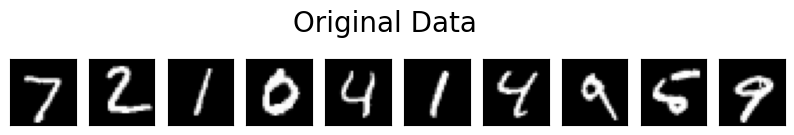

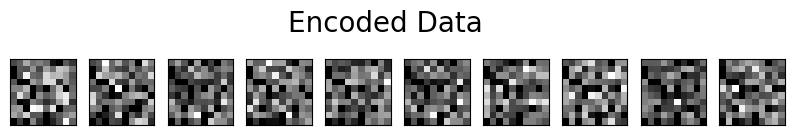

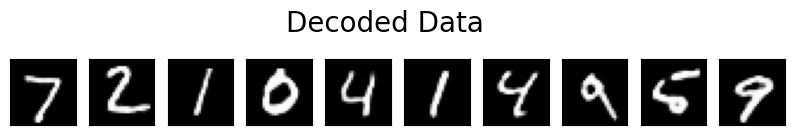

In [22]:
show_data(X_test, title='Original Data')
show_data(encoded_data, height=10, width=10, title='Encoded Data')
show_data(decoded_data, title='Decoded Data')